Frecuencia dominante encontrada: 1000.00 Hz


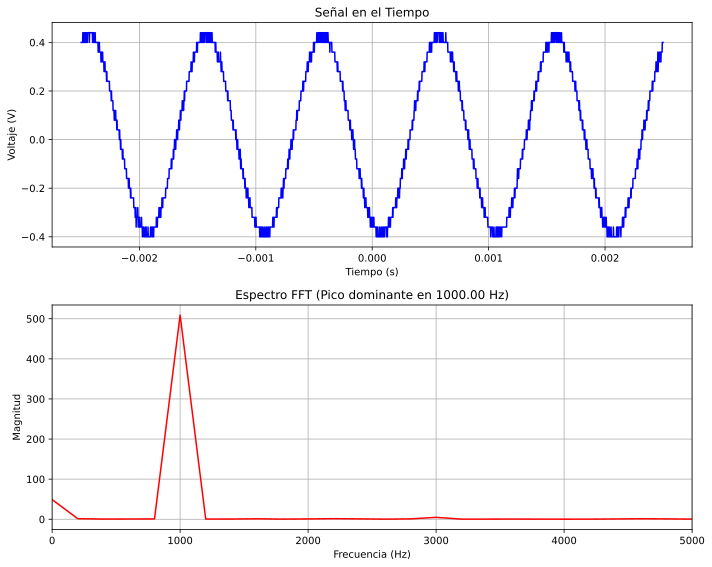

In [8]:
%config InlineBackend.figure_format = 'svg'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# Carga tu archivo CSV (reemplaza 'tu_archivo.csv' con el nombre real)
# Tektronix guarda Tiempo en la columna 3 y Voltaje en la 4 (índices base 0)
df = pd.read_csv('ALL0006\F0006CH3.CSV', usecols=[3, 4], names=['Tiempo', 'Voltaje'])

# Convertir a arreglos de numpy
t = df['Tiempo'].values
v = df['Voltaje'].values

# Calcular el intervalo de muestreo (Sample Interval)
dt = t[1] - t[0]

# --- 1. Calcular la frecuencia usando FFT ---
N = len(t)
yf = fft(v)
xf = fftfreq(N, dt)[:N//2]  # Tomar solo frecuencias positivas
magnitud = np.abs(yf[0:N//2])

# Encontrar el índice de la frecuencia dominante 
# (empezamos desde 1 para ignorar la componente de corriente directa/offset en 0 Hz)
idx_max = np.argmax(magnitud[1:]) + 1
frecuencia_dominante = xf[idx_max]

print(f"Frecuencia dominante encontrada: {frecuencia_dominante:.2f} Hz")

# --- 2. Graficar la señal y el espectro ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Señal en el tiempo
ax1.plot(t, v, color='b')
ax1.set_title("Señal en el Tiempo")
ax1.set_xlabel("Tiempo (s)")
ax1.set_ylabel("Voltaje (V)")
ax1.grid(True)

# Espectro de frecuencias
ax2.plot(xf, magnitud, color='r')
ax2.set_title(f"Espectro FFT (Pico dominante en {frecuencia_dominante:.2f} Hz)")
ax2.set_xlabel("Frecuencia (Hz)")
ax2.set_ylabel("Magnitud")
# Limitamos el eje X a 5 veces la frecuencia dominante para observar bien el pico
ax2.set_xlim(0, frecuencia_dominante * 5) 
ax2.grid(True)

plt.tight_layout()
plt.show()

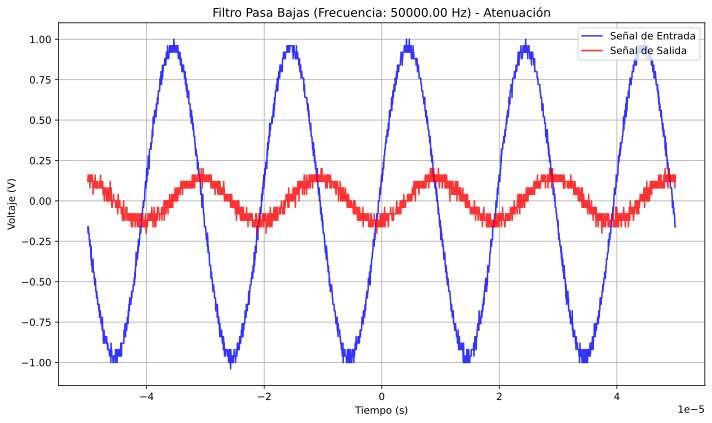

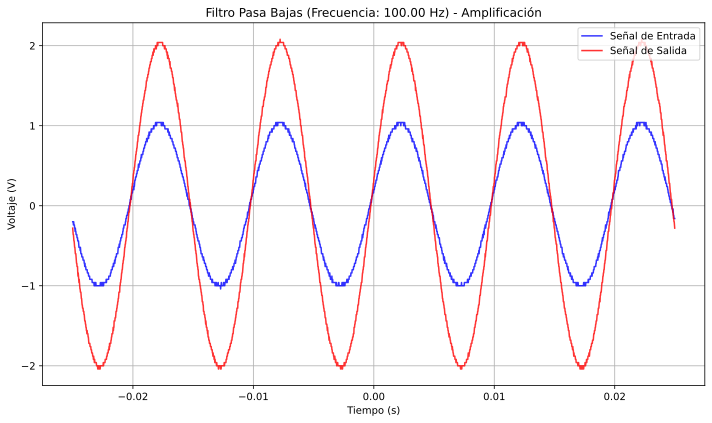

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

def opamp_pb(archivo_entrada, archivo_salida):
    atenuacion = False
    # Cargar datos de entrada y salida
    df_in = pd.read_csv(archivo_entrada, usecols=[3, 4], names=['Tiempo', 'Voltaje'])
    df_out = pd.read_csv(archivo_salida, usecols=[3, 4], names=['Tiempo', 'Voltaje'])

    # Convertir a arreglos
    t_in = df_in['Tiempo'].values
    v_in = df_in['Voltaje'].values
    t_out = df_out['Tiempo'].values
    v_out = df_out['Voltaje'].values

    if max(v_in) > max(v_out):
        atenuacion = True
        #print("Señal de salida atenuada respecto a la señal de entrada.")
        #print(atenuacion)
    else:
        atenuacion = False
        #print("Señal de salida amplificada respecto a la señal de entrada.")
    #print(max(v_in), max(v_out))
    #print(atenuacion)
    

    # Calcular FFT solo para la señal de entrada para obtener la frecuencia
    dt = t_in[1] - t_in[0]
    N = len(t_in)
    yf = fft(v_in)
    xf = fftfreq(N, dt)[:N//2]
    magnitud = np.abs(yf[0:N//2])

    # Extraer la frecuencia dominante (omitiendo el componente DC en 0 Hz)
    idx_max = np.argmax(magnitud[1:]) + 1
    frecuencia_dominante = xf[idx_max]

    # Crear la gráfica
    plt.figure(figsize=(10, 6))
    
    # Graficar ambas señales
    plt.plot(t_in, v_in, label='Señal de Entrada', color='blue', alpha=0.8)
    plt.plot(t_out, v_out, label='Señal de Salida', color='red', alpha=0.8)

    # Configurar el título dinámico con la frecuencia calculada
    #print(atenuacion)
    if atenuacion:
        plt.title(f"Filtro Pasa Bajas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Atenuación")
    else:
        plt.title(f"Filtro Pasa Bajas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Amplificación")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Voltaje (V)")
    plt.legend(loc="upper right")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

# Solo cambia los nombres por tus archivos reales
opamp_pb('TEK0003.CSV', 'TEK0002.CSV')
opamp_pb('TEK0004.CSV', 'TEK0005.CSV')

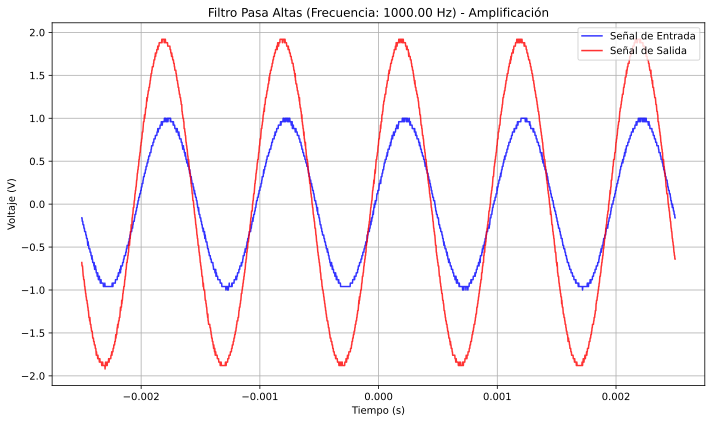

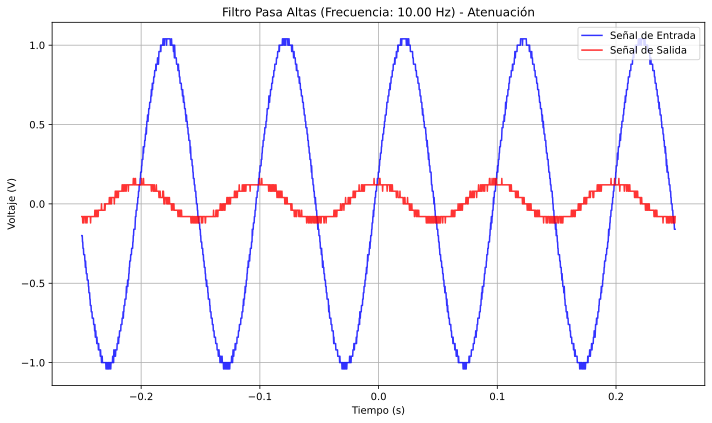

In [10]:
def opamp_pa(archivo_entrada, archivo_salida):
    atenuacion = False
    # Cargar datos de entrada y salida
    df_in = pd.read_csv(archivo_entrada, usecols=[3, 4], names=['Tiempo', 'Voltaje'])
    df_out = pd.read_csv(archivo_salida, usecols=[3, 4], names=['Tiempo', 'Voltaje'])

    # Convertir a arreglos
    t_in = df_in['Tiempo'].values
    v_in = df_in['Voltaje'].values
    t_out = df_out['Tiempo'].values
    v_out = df_out['Voltaje'].values

    if max(v_in) > max(v_out):
        atenuacion = True
        #print("Señal de salida atenuada respecto a la señal de entrada.")
        #print(atenuacion)
    else:
        atenuacion = False
        #print("Señal de salida amplificada respecto a la señal de entrada.")
    #print(max(v_in), max(v_out))
    #print(atenuacion)
    

    # Calcular FFT solo para la señal de entrada para obtener la frecuencia
    dt = t_in[1] - t_in[0]
    N = len(t_in)
    yf = fft(v_in)
    xf = fftfreq(N, dt)[:N//2]
    magnitud = np.abs(yf[0:N//2])

    # Extraer la frecuencia dominante (omitiendo el componente DC en 0 Hz)
    idx_max = np.argmax(magnitud[1:]) + 1
    frecuencia_dominante = xf[idx_max]

    # Crear la gráfica
    plt.figure(figsize=(10, 6))
    
    # Graficar ambas señales
    plt.plot(t_in, v_in, label='Señal de Entrada', color='blue', alpha=0.8)
    plt.plot(t_out, v_out, label='Señal de Salida', color='red', alpha=0.8)

    # Configurar el título dinámico con la frecuencia calculada
    #print(atenuacion)
    if atenuacion:
        plt.title(f"Filtro Pasa Altas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Atenuación")
    else:
        plt.title(f"Filtro Pasa Altas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Amplificación")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Voltaje (V)")
    plt.legend(loc="upper right")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


opamp_pa('TEK0007.CSV', 'TEK0006.CSV')
opamp_pa('TEK0008.CSV', 'TEK0009.CSV')

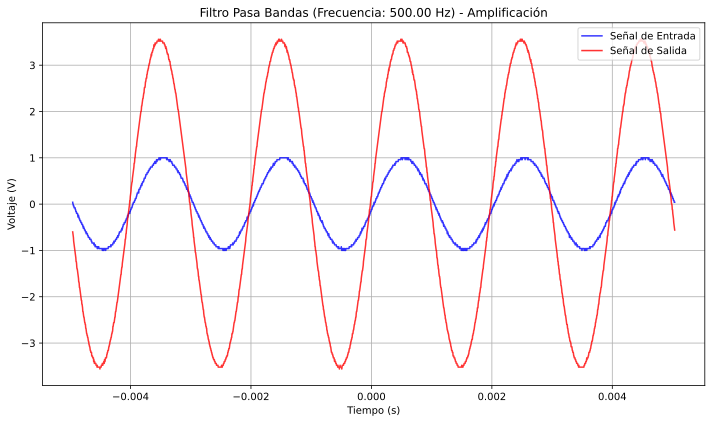

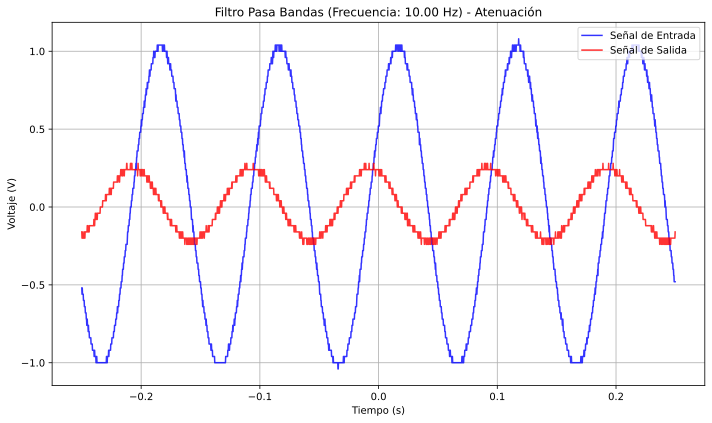

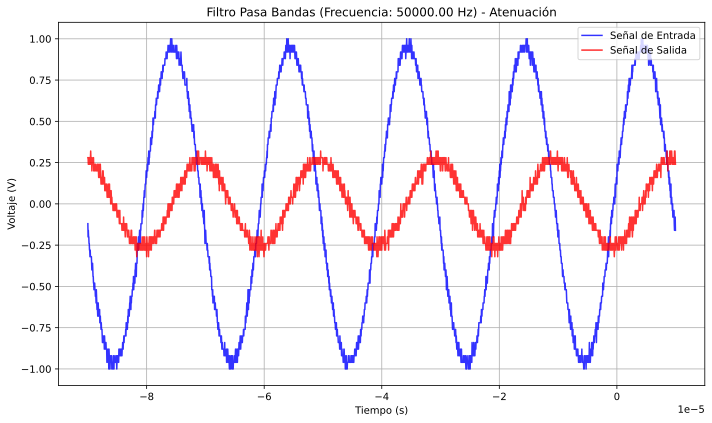

In [11]:
def opamp_pba(archivo_entrada, archivo_salida):
    atenuacion = False
    # Cargar datos de entrada y salida
    df_in = pd.read_csv(archivo_entrada, usecols=[3, 4], names=['Tiempo', 'Voltaje'])
    df_out = pd.read_csv(archivo_salida, usecols=[3, 4], names=['Tiempo', 'Voltaje'])

    # Convertir a arreglos
    t_in = df_in['Tiempo'].values
    v_in = df_in['Voltaje'].values
    t_out = df_out['Tiempo'].values
    v_out = df_out['Voltaje'].values

    if max(v_in) > max(v_out):
        atenuacion = True
        #print("Señal de salida atenuada respecto a la señal de entrada.")
        #print(atenuacion)
    else:
        atenuacion = False
        #print("Señal de salida amplificada respecto a la señal de entrada.")
    #print(max(v_in), max(v_out))
    #print(atenuacion)
    

    # Calcular FFT solo para la señal de entrada para obtener la frecuencia
    dt = t_in[1] - t_in[0]
    N = len(t_in)
    yf = fft(v_in)
    xf = fftfreq(N, dt)[:N//2]
    magnitud = np.abs(yf[0:N//2])

    # Extraer la frecuencia dominante (omitiendo el componente DC en 0 Hz)
    idx_max = np.argmax(magnitud[1:]) + 1
    frecuencia_dominante = xf[idx_max]

    # Crear la gráfica
    plt.figure(figsize=(10, 6))
    
    # Graficar ambas señales
    plt.plot(t_in, v_in, label='Señal de Entrada', color='blue', alpha=0.8)
    plt.plot(t_out, v_out, label='Señal de Salida', color='red', alpha=0.8)

    # Configurar el título dinámico con la frecuencia calculada
    #print(atenuacion)
    if atenuacion:
        plt.title(f"Filtro Pasa Bandas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Atenuación")
    else:
        plt.title(f"Filtro Pasa Bandas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Amplificación")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Voltaje (V)")
    plt.legend(loc="upper right")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


opamp_pba('TEK0011.CSV', 'TEK0010.CSV')
opamp_pba('TEK0012.CSV', 'TEK0013.CSV')
opamp_pba('TEK0015.CSV', 'TEK0014.CSV')



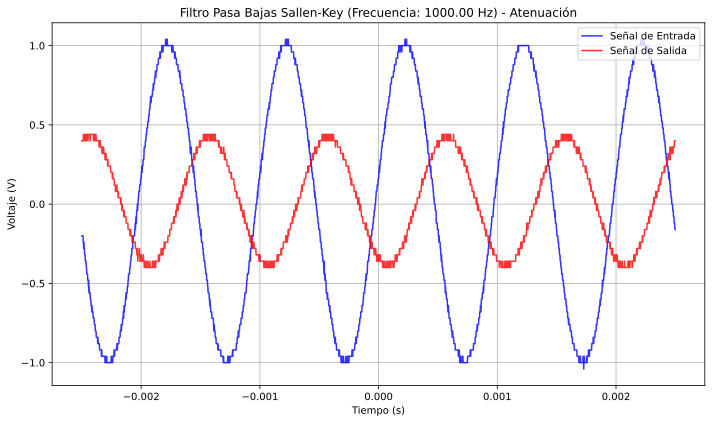

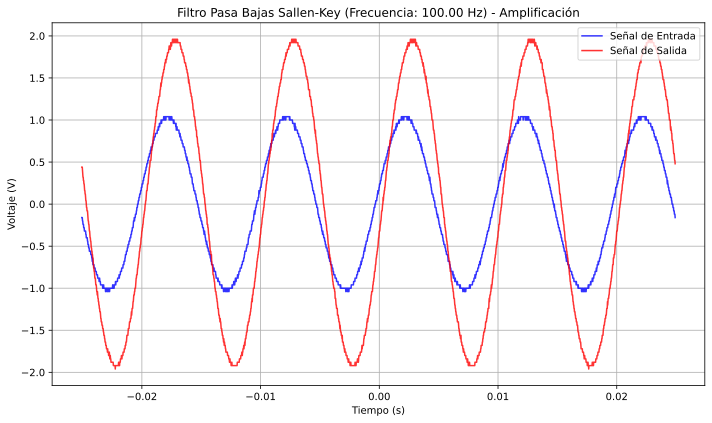

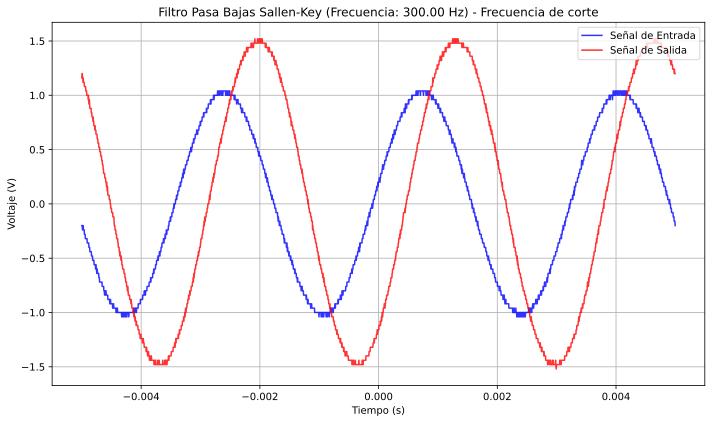

In [12]:
def opamp_sk(archivo_entrada, archivo_salida):
    atenuacion = False
    # Cargar datos de entrada y salida
    df_in = pd.read_csv(archivo_entrada, usecols=[3, 4], names=['Tiempo', 'Voltaje'])
    df_out = pd.read_csv(archivo_salida, usecols=[3, 4], names=['Tiempo', 'Voltaje'])

    # Convertir a arreglos
    t_in = df_in['Tiempo'].values
    v_in = df_in['Voltaje'].values
    t_out = df_out['Tiempo'].values
    v_out = df_out['Voltaje'].values

    if max(v_in) > max(v_out):
        atenuacion = True
        #print("Señal de salida atenuada respecto a la señal de entrada.")
        #print(atenuacion)
    else:
        atenuacion = False
        #print("Señal de salida amplificada respecto a la señal de entrada.")
    #print(max(v_in), max(v_out))
    #print(atenuacion)
    

    # Calcular FFT solo para la señal de entrada para obtener la frecuencia
    dt = t_in[1] - t_in[0]
    N = len(t_in)
    yf = fft(v_in)
    xf = fftfreq(N, dt)[:N//2]
    magnitud = np.abs(yf[0:N//2])

    # Extraer la frecuencia dominante (omitiendo el componente DC en 0 Hz)
    idx_max = np.argmax(magnitud[1:]) + 1
    frecuencia_dominante = xf[idx_max]

    # Crear la gráfica
    plt.figure(figsize=(10, 6))
    
    # Graficar ambas señales
    plt.plot(t_in, v_in, label='Señal de Entrada', color='blue', alpha=0.8)
    plt.plot(t_out, v_out, label='Señal de Salida', color='red', alpha=0.8)

    # Configurar el título dinámico con la frecuencia calculada
    #print(atenuacion)
    if atenuacion:
        plt.title(f"Filtro Pasa Bajas Sallen-Key (Frecuencia: {frecuencia_dominante:.2f} Hz) - Atenuación")
    else:
        plt.title(f"Filtro Pasa Bajas Sallen-Key (Frecuencia: {frecuencia_dominante:.2f} Hz) - Amplificación")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Voltaje (V)")
    plt.legend(loc="upper right")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


opamp_sk('ALL0006\F0006CH2.CSV', 'ALL0006\F0006CH3.CSV')
opamp_sk('ALL0004\F0004CH2.CSV', 'ALL0004\F0004CH3.CSV')

def opamp_sk_fc(archivo_entrada, archivo_salida):
    atenuacion = False
    # Cargar datos de entrada y salida
    df_in = pd.read_csv(archivo_entrada, usecols=[3, 4], names=['Tiempo', 'Voltaje'])
    df_out = pd.read_csv(archivo_salida, usecols=[3, 4], names=['Tiempo', 'Voltaje'])

    # Convertir a arreglos
    t_in = df_in['Tiempo'].values
    v_in = df_in['Voltaje'].values
    t_out = df_out['Tiempo'].values
    v_out = df_out['Voltaje'].values

    if max(v_in) > max(v_out):
        atenuacion = True
        #print("Señal de salida atenuada respecto a la señal de entrada.")
        #print(atenuacion)
    else:
        atenuacion = False
        #print("Señal de salida amplificada respecto a la señal de entrada.")
    #print(max(v_in), max(v_out))
    #print(atenuacion)
    

    # Calcular FFT solo para la señal de entrada para obtener la frecuencia
    dt = t_in[1] - t_in[0]
    N = len(t_in)
    yf = fft(v_in)
    xf = fftfreq(N, dt)[:N//2]
    magnitud = np.abs(yf[0:N//2])

    # Extraer la frecuencia dominante (omitiendo el componente DC en 0 Hz)
    idx_max = np.argmax(magnitud[1:]) + 1
    frecuencia_dominante = xf[idx_max]

    # Crear la gráfica
    plt.figure(figsize=(10, 6))
    
    # Graficar ambas señales
    plt.plot(t_in, v_in, label='Señal de Entrada', color='blue', alpha=0.8)
    plt.plot(t_out, v_out, label='Señal de Salida', color='red', alpha=0.8)

    # Configurar el título dinámico con la frecuencia calculada
    #print(atenuacion)
    if atenuacion:
        plt.title(f"Filtro Pasa Bajas Sallen-Key (Frecuencia: {frecuencia_dominante:.2f} Hz) - Frecuencia de corte")
    else:
        plt.title(f"Filtro Pasa Bajas Sallen-Key (Frecuencia: {frecuencia_dominante:.2f} Hz) - Frecuencia de corte")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Voltaje (V)")
    plt.legend(loc="upper right")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

opamp_sk_fc('ALL0005\F0005CH2.CSV', 'ALL0005\F0005CH3.CSV')



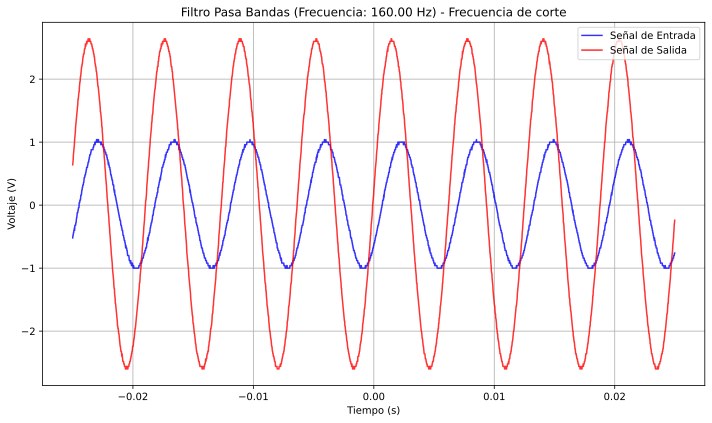

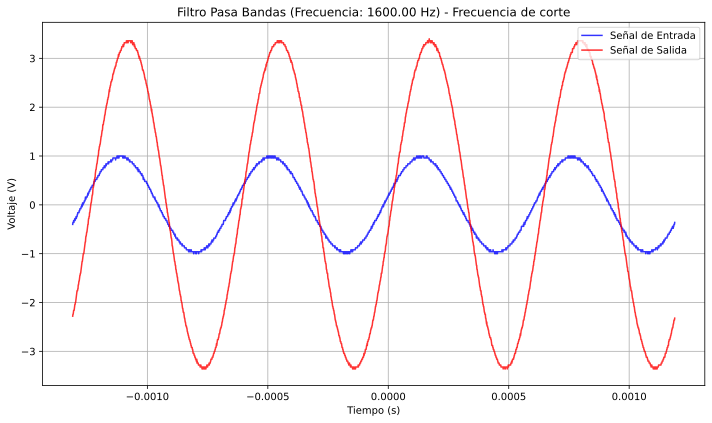

In [13]:
def opamp_pba_fc(archivo_entrada, archivo_salida):
    atenuacion = False
    # Cargar datos de entrada y salida
    df_in = pd.read_csv(archivo_entrada, usecols=[3, 4], names=['Tiempo', 'Voltaje'])
    df_out = pd.read_csv(archivo_salida, usecols=[3, 4], names=['Tiempo', 'Voltaje'])

    # Convertir a arreglos
    t_in = df_in['Tiempo'].values
    v_in = df_in['Voltaje'].values
    t_out = df_out['Tiempo'].values
    v_out = df_out['Voltaje'].values

    if max(v_in) > max(v_out):
        atenuacion = True
        #print("Señal de salida atenuada respecto a la señal de entrada.")
        #print(atenuacion)
    else:
        atenuacion = False
        #print("Señal de salida amplificada respecto a la señal de entrada.")
    #print(max(v_in), max(v_out))
    #print(atenuacion)
    

    # Calcular FFT solo para la señal de entrada para obtener la frecuencia
    dt = t_in[1] - t_in[0]
    N = len(t_in)
    yf = fft(v_in)
    xf = fftfreq(N, dt)[:N//2]
    magnitud = np.abs(yf[0:N//2])

    # Extraer la frecuencia dominante (omitiendo el componente DC en 0 Hz)
    idx_max = np.argmax(magnitud[1:]) + 1
    frecuencia_dominante = xf[idx_max]

    # Crear la gráfica
    plt.figure(figsize=(10, 6))
    
    # Graficar ambas señales
    plt.plot(t_in, v_in, label='Señal de Entrada', color='blue', alpha=0.8)
    plt.plot(t_out, v_out, label='Señal de Salida', color='red', alpha=0.8)

    # Configurar el título dinámico con la frecuencia calculada
    #print(atenuacion)
    if atenuacion:
        plt.title(f"Filtro Pasa Bandas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Frecuencia de corte")
    else:
        plt.title(f"Filtro Pasa Bandas (Frecuencia: {frecuencia_dominante:.2f} Hz) - Frecuencia de corte")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Voltaje (V)")
    plt.legend(loc="upper right")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

opamp_pba_fc('ALL0002\F0002CH2.CSV', 'ALL0002\F0002CH3.CSV')
opamp_pba_fc('ALL0003\F0003CH2.CSV', 'ALL0003\F0003CH3.CSV')
